Realizado por:
Andrea Bonilla
July Aparicio
Ioshua Castillejos

# Clasificación de Sentimientos de Reseñas de Películas en IMDb con Redes Neuronales Recurrentes
## A - Objetivo

Desarrollar un método basado en redes neuronales recurrentes que permita clasificar con precisión las reseñas de películas en IMDb en una de las dos
categorías: positiva o negativa

## B - Conjunto de datos

Los datos corresponden a un dataset de reseñas de películas en IMDb,
disponibles en el siguiente enlace. El dataset contiene miles de reseñas
etiquetadas con su correspondiente rating y etiqueta de sentimiento (positivo o
negativo)

## C - Actividades por realizar
1. Preprocesamiento de las reseñas: Construir un pipeline que permita limpiar y
tokenizar las reseñas de texto, convirtiéndolas en secuencias numéricas
utilizando embeddings
2. Desarrollo de la arquitectura de red neuronal recurrente: Implementar una
RNN (por ejemplo, LSTM o GRU) para la clasificación de las reseñas en dos
categorías. La arquitectura de la red es de libre elección, pero se sugiere incluir
capas de embedding, capas recurrentes y una capa densa de salida con
activación sigmoide. Justificar la elección de cada capa del modelo.
3. Entrenamiento y evaluación del modelo: Dividir el dataset en conjuntos de
entrenamiento, validación y prueba. Entrenar el modelo utilizando el conjunto de
entrenamiento y evaluar su rendimiento con el conjunto de prueba, reportando
métricas de precisión, recall y F1-score.

### 1. Librerías

In [1]:
# Librerías requeridas
# PyTorch para construir y entrenar las redes
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split


import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, random_split

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

from time import time
from gensim.models import Word2Vec
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

import copy

# Para descargar los recursos desde la red con proxy (error de certificado SSL)
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

# Se descargan los recursos de NLTK si no están instalados
for recurso, ruta in [('punkt', 'tokenizers/punkt'),
                      ('punkt_tab', 'tokenizers/punkt_tab'),
                      ('stopwords', 'corpora/stopwords')]:
    try:
        nltk.data.find(ruta)
    except LookupError:
        nltk.download(recurso, quiet=True)

# Semillas
torch.manual_seed(42)
np.random.seed(42)

# Se usa GPU si está disponible
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Usando dispositivo: cuda


### 2. Importar los datos

In [2]:
GHI = pd.read_csv('movie.csv')
GHI.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    40000 non-null  object
 1   label   40000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 625.1+ KB


### 3. Exploración de datos

In [3]:
GHI.head()

,text,label
0,I grew up (b. 1965) watching and loving the Th...,0
1,"When I put this movie in my DVD player, and sa...",0
2,Why do people who do not know what a particula...,0
3,Even though I have great interest in Biblical ...,0
4,Im a die hard Dads Army fan and nothing will e...,1


In [4]:
GHI['label'].value_counts()

label
0    20019
1    19981
Name: count, dtype: int64

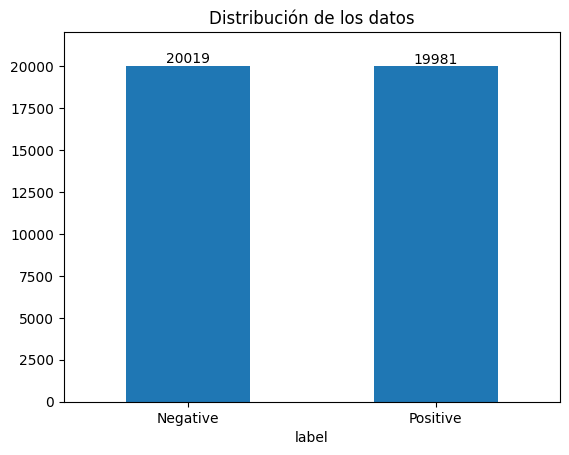

In [5]:
ax = GHI.groupby('label').count().plot(kind='bar', title='Distribución de los datos',
                                       legend=False)
ax.set_xticklabels(['Negative', 'Positive'], rotation=0)

for container in ax.containers:
    ax.bar_label(container)

ax.margins(y=0.1)  # espacio para las etiquetas


In [6]:
longitudes = GHI['text'].str.split().str.len()
print(f"Textos muy cortos (<5 palabras): {(longitudes < 5).sum()}")
print(f"Textos muy largos (>1000 palabras): {(longitudes > 1000).sum()}")
print(f"Filas con registros nulos: {GHI['text'].isnull().sum()}")
print(f"Filas invalidas: {GHI['text'].isna().sum()}")
print(f"Filas duplicadas: {GHI['text'].duplicated().sum()}")

Textos muy cortos (<5 palabras): 1
Textos muy largos (>1000 palabras): 60
Filas con registros nulos: 0
Filas invalidas: 0
Filas duplicadas: 277


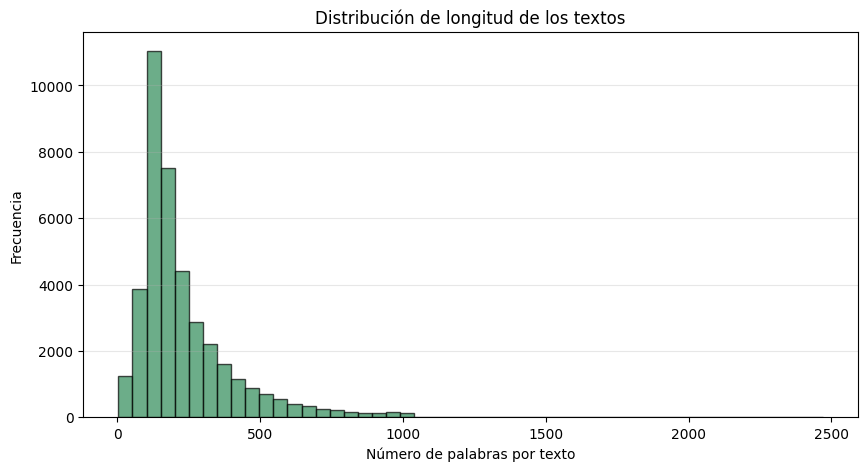

count    40000.000000
mean       231.339250
std        171.194123
min          4.000000
25%        126.000000
50%        173.000000
75%        282.000000
max       2470.000000
Name: text, dtype: float64


In [7]:
longitudes = GHI['text'].str.split().str.len()

plt.figure(figsize=(10,5))
plt.hist(longitudes, bins=50, color='seagreen', edgecolor='black', alpha=0.7)
plt.xlabel('Número de palabras por texto')
plt.ylabel('Frecuencia')
plt.title('Distribución de longitud de los textos')
plt.grid(axis='y', alpha=0.3)
plt.show()

print(longitudes.describe())

Hallazgos de la exploración de datos.

Las dos clases están casi balanceadas (20.019 reseñas negativas y 19.981 positivas), por lo que no fue necesario balancear los datos. No hay valores nulos, pero sí 277 reseñas repetidas, que se eliminan antes de dividir los datos. En promedio las reseñas tienen 231 palabras y la mediana es de 173; la más corta tiene 4 palabras y la más larga 2.470, por eso el histograma tiene una cola larga hacia la derecha. Solo una reseña tiene menos de 5 palabras y 60 tienen más de 1.000.

### 4. Separación de datos

Primero se eliminan las reseñas duplicadas, para que una misma reseña no quede a la vez en entrenamiento y en prueba; quedan 39.723 registros. Después los datos se dividen en 70 % entrenamiento (27.806), 15 % validación (5.958) y 15 % prueba (5.959), estratificando por la etiqueta para mantener la proporción de clases. La división usa la semilla 42.

In [8]:
# Se quitan los duplicados antes de dividir
GHI = GHI.drop_duplicates(subset='text').reset_index(drop=True)
print(f"Registros tras eliminar duplicados: {len(GHI)}")

SEED = 42

# 70% train, 15% validación, 15% prueba
train_GHI, resto = train_test_split(GHI, test_size=0.30, stratify=GHI["label"], random_state=SEED)
val_GHI, test_GHI = train_test_split(resto, test_size=0.50, stratify=resto["label"], random_state=SEED)
print(f"Datos entrenamiento: {len(train_GHI)}\nDatos validacion: {len(val_GHI)} \nDatos prueba: {len(test_GHI)}")

Registros tras eliminar duplicados: 39723
Datos entrenamiento: 27806
Datos validacion: 5958 
Datos prueba: 5959


### 5. Función de limpieza de textos

La función `limpiar_texto` convierte las entidades HTML (`&amp;`), quita las etiquetas HTML como `<br />` y las URLs, y pasa todo a minúsculas. Las negaciones contraídas se separan (*won't* → *will not*, *can't* → *can not*, *didn't* → *did not*), las demás contracciones (*'s*, *'re*, *'ll*...) se eliminan y se dejan solo letras.

Después se quitan las stopwords de NLTK y las palabras de una sola letra, pero se conservan *no*, *nor*, *not*, *but*, *very*, *too*, *against* y *only*, porque cambian el sentido de la reseña. Por último cada palabra se reduce a su raíz con el stemmer de Porter (*movies* → *movi*). La limpieza se aplica a los tres conjuntos y el resultado queda en la columna `palabras_limpias`.

In [9]:
import re
import html

# Se conservan las negaciones y palabras que cambian el sentido
conservar = {'no', 'nor', 'not', 'but', 'very', 'too', 'against', 'only'}
stop_words = set(stopwords.words('english')) - conservar

def limpiar_texto(texto, quitar_stopwords=True):
    texto = html.unescape(texto)
    texto = re.sub(r'<[^>]+>', ' ', texto)  # html
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)  # urls
    texto = texto.lower().replace('\u2019', "'")  # minúsculas
    texto = re.sub(r"\bwon't\b", 'will not', texto)  # negaciones
    texto = re.sub(r"\bcan't\b", 'can not', texto)
    texto = re.sub(r"n't\b", ' not', texto)
    texto = re.sub(r"'(s|re|ve|d|ll|m)\b", ' ', texto)  # contracciones
    texto = re.sub(r'[^a-z\s]', ' ', texto)  # solo letras
    palabras_limpias = texto.split()
    if quitar_stopwords:
        palabras_limpias = [t for t in palabras_limpias if t not in stop_words and len(t) > 1]
        palabras_limpias = [stemmer.stem(t) for t in palabras_limpias]
    # Retorna la lista de palabras limpias
    return palabras_limpias

print(limpiar_texto("I didn't like it.<br /><br />It WASN'T good &amp; I can't recommend it!!"))

# Limpieza de train, validación y prueba
for conjunto in (train_GHI, val_GHI, test_GHI):
    conjunto['palabras_limpias'] = conjunto['text'].apply(limpiar_texto)

['not', 'like', 'not', 'good', 'not', 'recommend']


### 6. Embeddings

Se entrena un modelo Word2Vec con las reseñas de entrenamiento ya limpias, con vectores de 100 dimensiones y ventana de 5. Como las palabras pasaron por stemming, las más parecidas a *great* aparecen como raíces (*excel*, *fantast*, *amaz*).

In [10]:
from gensim.models import Word2Vec

EMB_DIM = 100

w2v = Word2Vec(
    sentences=train_GHI["palabras_limpias"].tolist(),
    vector_size=EMB_DIM,
    window=5,
    min_count=1,
    workers=4,
    seed=42,
)

print(f"Palabras en el modelo Word2Vec: {len(w2v.wv):,}")
print("Similares a 'great':", w2v.wv.most_similar('great', topn=5))

Palabras en el modelo Word2Vec: 53,987
Similares a 'great': [('excel', 0.755484938621521), ('fantast', 0.7384083271026611), ('fine', 0.733458399772644), ('good', 0.6779460310935974), ('amaz', 0.6554599404335022)]


### 7. Matriz con embeddings

El vocabulario se construye solo con los datos de entrenamiento: el 0 es para el padding, el 1 para las palabras desconocidas y el resto para las 19.998 palabras más frecuentes (20.000 índices en total). Cada reseña se convierte en una secuencia de 300 índices; si es más larga se conserva el inicio y si es más corta se rellena con ceros al inicio.

Con el vocabulario se arma la matriz de embeddings: cada fila toma el vector de Word2Vec de su palabra y el padding queda en ceros. Las palabras sin vector tomarían valores aleatorios de una normal con media 0 y desviación 0.1, pero como Word2Vec se entrenó con `min_count=1`, todas las palabras del vocabulario tienen vector.

In [11]:
from collections import Counter

MAX_VOCAB = 20000
MAX_LEN = 300

# Vocabulario con los datos de train. 0 = padding, 1 = palabra desconocida
contador = Counter(t for toks in train_GHI["palabras_limpias"] for t in toks)
palabras = [p for p, _ in contador.most_common(MAX_VOCAB - 2)]
word2idx = {p: i + 2 for i, p in enumerate(palabras)}
VOCAB_SIZE = len(word2idx) + 2

def codificar(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][:MAX_LEN]
    # padding al inicio
    return [0] * (MAX_LEN - len(ids)) + ids

In [12]:
# Matriz de embeddings con los vectores de Word2Vec
matriz_emb = np.random.normal(0, 0.1, (VOCAB_SIZE, EMB_DIM)).astype("float32")
matriz_emb[0] = 0.0  # padding
encontradas = 0
for palabra, idx in word2idx.items():
    if palabra in w2v.wv:
        matriz_emb[idx] = w2v.wv[palabra]
        encontradas += 1
print(f"Palabras con vector Word2Vec: {encontradas:,} / {len(word2idx):,}")


Palabras con vector Word2Vec: 19,998 / 19,998


### 8. Creación de tensores

Las secuencias de cada conjunto se pasan a tensores: `X` con los índices de las palabras y `y` con la etiqueta (0 = negativa, 1 = positiva). Los lotes son de 128 para entrenamiento, que se mezclan en cada época, y de 256 para validación y prueba.

In [13]:
# Tensores: X con las palabras limpias codificadas
# y con las etiquetas (0 y 1)
def a_tensores(frame):
    X = torch.tensor([codificar(t) for t in frame["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(frame["label"].values, dtype=torch.float32)
    return X, y

X_train, y_train = a_tensores(train_GHI)
X_val, y_val = a_tensores(val_GHI)
X_test, y_test = a_tensores(test_GHI)

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=128, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=256)
print(X_train.shape, X_val.shape, X_test.shape)

torch.Size([27806, 300]) torch.Size([5958, 300]) torch.Size([5959, 300])


### 9. Modelo

La primera capa es un embedding de 100 dimensiones inicializado con los vectores de Word2Vec. De esta forma la red no empieza desde cero y ya tiene una idea de qué palabras son parecidas, por ejemplo *great* y *excellent*. La capa se deja entrenable para que los vectores se ajusten a la clasificación de sentimiento. El índice 0 corresponde al padding.

Después del embedding se agrega un dropout de 0.3, ya que con 20.000 palabras en el vocabulario el modelo puede aprenderse palabras de memoria y no generalizar.

Luego van dos capas LSTM de 128 unidades, con un dropout de 0.3 entre ellas. Se escogió LSTM en lugar de una RNN simple porque las reseñas son largas (se cortan en 300 palabras) y la RNN simple olvida lo que leyó al principio por el desvanecimiento del gradiente. De la LSTM se toma el último estado oculto de la segunda capa, que resume toda la reseña.

Ese vector pasa por otro dropout y por una capa densa con una sola neurona y activación sigmoide, que da la probabilidad de que la reseña sea positiva. Si es 0.5 o más, la reseña se clasifica como positiva. La función de pérdida es `BCELoss`.

Para el entrenamiento se usa Adam con tasa de aprendizaje de 0.001 y weight decay de 1e-5, y se limita la norma del gradiente a 1.0, porque en las LSTM los gradientes a veces se disparan.

In [14]:
class SentimentLSTM(nn.Module):
    def __init__(self, vocab_size, emb_dim=100, hidden_dim=128, num_layers=2, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.emb_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        emb = self.emb_dropout(self.embedding(x))
        _, (h_n, _) = self.lstm(emb)
        h = self.dropout(h_n[-1])  # último estado oculto
        return self.sigmoid(self.fc(h)).squeeze(1)

modelo = SentimentLSTM(VOCAB_SIZE, EMB_DIM).to(device)
modelo.embedding.weight.data.copy_(torch.tensor(matriz_emb))
modelo.embedding.weight.requires_grad = True
criterio = nn.BCELoss()
optimizador = optim.Adam(modelo.parameters(), lr=1e-3, weight_decay=1e-5)  # regularización L2
# Se reduce el lr a la mitad si la pérdida de validación no baja
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizador, mode="min", factor=0.5, patience=1)

print(modelo)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo.parameters() if p.requires_grad):,}")

SentimentLSTM(
  (embedding): Embedding(20000, 100, padding_idx=0)
  (emb_dropout): Dropout(p=0.3, inplace=False)
  (lstm): LSTM(100, 128, num_layers=2, batch_first=True, dropout=0.3)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)
Parámetros entrenables: 2,249,985


### 10. Entrenamiento con validación

En cada época el modelo se entrena con `train_loader` y se evalúa con `val_loader`. Se guarda el modelo con menor pérdida de validación y el entrenamiento se detiene si esta no mejora en 10 épocas seguidas (early stopping), con un máximo de 50. Cuando la pérdida de validación no baja, `ReduceLROnPlateau` reduce la tasa de aprendizaje a la mitad. El conjunto de prueba no se usa en esta parte.

In [15]:
def ejecutar_epoca(loader, entrenar):
    modelo.train() if entrenar else modelo.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            prob = modelo(xb)
            perdida = criterio(prob, yb)
            if entrenar:
                optimizador.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                optimizador.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((prob >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS = 50
PACIENCIA = 10

historial = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_loss = float("inf")
mejor_estado = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS + 1):
    tr_loss, tr_acc = ejecutar_epoca(train_loader, entrenar=True)
    va_loss, va_acc = ejecutar_epoca(val_loader, entrenar=False)
    scheduler.step(va_loss)
    for k, v in zip(historial, (tr_loss, va_loss, tr_acc, va_acc)):
        historial[k].append(v)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador.param_groups[0]['lr']:.1e}")

    if va_loss < mejor_val_loss:
        mejor_val_loss = va_loss
        mejor_estado = copy.deepcopy(modelo.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA:
            print(f"Early stopping: la pérdida de validación no mejora hace {PACIENCIA} épocas")
            break

modelo.load_state_dict(mejor_estado)  # mejor modelo
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val loss: {mejor_val_loss:.4f}")

Época  1 | train loss 0.4652 acc 0.7836 | val loss 0.3647 acc 0.8499 | lr 1.0e-03
Época  2 | train loss 0.3562 acc 0.8497 | val loss 0.3047 acc 0.8696 | lr 1.0e-03
Época  3 | train loss 0.3003 acc 0.8779 | val loss 0.2804 acc 0.8842 | lr 1.0e-03
Época  4 | train loss 0.2600 acc 0.8978 | val loss 0.2630 acc 0.8964 | lr 1.0e-03
Época  5 | train loss 0.2200 acc 0.9158 | val loss 0.2560 acc 0.8996 | lr 1.0e-03
Época  6 | train loss 0.1808 acc 0.9317 | val loss 0.2862 acc 0.8990 | lr 1.0e-03
Época  7 | train loss 0.1475 acc 0.9468 | val loss 0.2655 acc 0.8914 | lr 5.0e-04
Época  8 | train loss 0.1075 acc 0.9622 | val loss 0.3106 acc 0.8959 | lr 5.0e-04
Época  9 | train loss 0.0878 acc 0.9710 | val loss 0.3448 acc 0.8951 | lr 2.5e-04
Época 10 | train loss 0.0745 acc 0.9752 | val loss 0.3745 acc 0.8958 | lr 2.5e-04
Época 11 | train loss 0.0651 acc 0.9785 | val loss 0.3803 acc 0.8969 | lr 1.3e-04
Época 12 | train loss 0.0605 acc 0.9814 | val loss 0.3926 acc 0.8927 | lr 1.3e-04
Época 13 | train

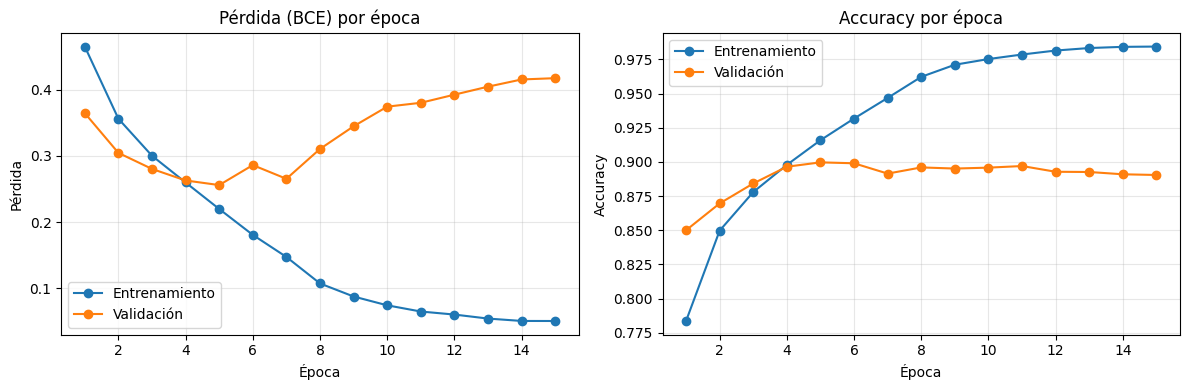

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial["train_loss"]) + 1)

axes[0].plot(epocas_x, historial["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

### 11. Evaluación en el conjunto de prueba

El mejor modelo se evalúa una sola vez con el 15 % de prueba, que no se usó ni para entrenar ni para escoger el modelo. Se reportan accuracy, precisión, recall y F1-score, junto con la matriz de confusión.

Accuracy : 0.8966
Precisión: 0.8860
Recall   : 0.9109
F1-score : 0.8983

              precision    recall  f1-score   support

    Negativa     0.9079    0.8823    0.8949      2973
    Positiva     0.8860    0.9109    0.8983      2986

    accuracy                         0.8966      5959
   macro avg     0.8970    0.8966    0.8966      5959
weighted avg     0.8969    0.8966    0.8966      5959



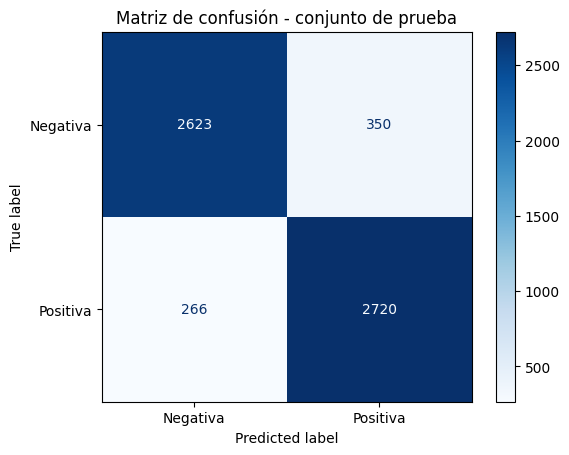

In [17]:
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

modelo.eval()
probs, reales = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        probs.append(modelo(xb.to(device)).cpu())
        reales.append(yb)
probs = torch.cat(probs).numpy()
y_real = torch.cat(reales).numpy().astype(int)
y_pred = (probs >= 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_real, y_pred):.4f}")
print(f"Precisión: {precision_score(y_real, y_pred):.4f}")
print(f"Recall   : {recall_score(y_real, y_pred):.4f}")
print(f"F1-score : {f1_score(y_real, y_pred):.4f}\n")
print(classification_report(y_real, y_pred, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real, y_pred),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - conjunto de prueba")
plt.show()

## Modelo con embeddings GloVe 300d (comparación con Word2Vec 100d)



### 12. Embeddings GloVe

Para comparar, también se prueban los vectores preentrenados de GloVe de 300 dimensiones. Si el archivo `glove.6B.300d.txt` está en la carpeta se lee de ahí; si no, se descarga con gensim (`glove-wiki-gigaword-300`). La matriz se arma en el mismo orden del vocabulario: las palabras que no aparecen en GloVe quedan con un vector aleatorio y el padding en ceros. Hay que tener en cuenta que, como las palabras pasaron por stemming, muchas no se encuentran en GloVe.

In [ ]:
import os
from gensim.models import KeyedVectors
import gensim.downloader as api

EMB_DIM_GLOVE = 300

if os.path.exists("glove.6B.300d.txt"):
    glove = KeyedVectors.load_word2vec_format("glove.6B.300d.txt", binary=False, no_header=True)
else:
    glove = api.load("glove-wiki-gigaword-300")

print(glove.most_similar("great", topn=5))
print(glove.most_similar("terrible", topn=5))

encontradas_glove = [p for p in word2idx if p in glove]
desv = np.std([glove[p] for p in encontradas_glove])
rng = np.random.default_rng(SEED)

emb_matrix_glove = rng.normal(scale=desv, size=(MAX_VOCAB, EMB_DIM_GLOVE)).astype(np.float32)
emb_matrix_glove[0] = 0
for palabra in encontradas_glove:
    emb_matrix_glove[word2idx[palabra]] = glove[palabra]
print(f"Palabras con vector de GloVe: {len(encontradas_glove):,} de {len(word2idx):,}")

del glove

### 13. Secuencias y tensores (GloVe)

Para este modelo se usan secuencias de 400 palabras. Si la reseña es más corta se rellena con ceros al inicio y si es más larga se conserva el final, que es donde suele ir la opinión final del autor. Los lotes son de 128 para entrenamiento y de 256 para validación y prueba.

In [ ]:
MAX_LEN_GLOVE = 400

def codificar_glove(tokens):
    ids = [word2idx.get(t, 1) for t in tokens][-MAX_LEN_GLOVE:]   # se deja el final de la reseña
    return [0] * (MAX_LEN_GLOVE - len(ids)) + ids

def a_tensores_glove(df):
    X = torch.tensor([codificar_glove(t) for t in df["palabras_limpias"]], dtype=torch.long)
    y = torch.tensor(df["label"].values, dtype=torch.float32)
    return X, y

X_train_glove, y_train_glove = a_tensores_glove(train_GHI)
X_val_glove, y_val_glove = a_tensores_glove(val_GHI)
X_test_glove, y_test_glove = a_tensores_glove(test_GHI)

train_loader_glove = DataLoader(TensorDataset(X_train_glove, y_train_glove), batch_size=128, shuffle=True)
val_loader_glove = DataLoader(TensorDataset(X_val_glove, y_val_glove), batch_size=256)
test_loader_glove = DataLoader(TensorDataset(X_test_glove, y_test_glove), batch_size=256)
print(X_train_glove.shape, X_val_glove.shape, X_test_glove.shape)

### 14. Modelo GloVe

El embedding se inicializa con la matriz de GloVe y se deja entrenable, seguido de un dropout de 0.3. Después hay una LSTM bidireccional de 128 unidades; se usa bidireccional porque a veces el sentido de una palabra depende de lo que viene después, como en "not bad at all". Cada palabra queda representada con un vector de 256 (128 por cada dirección).

En vez de usar solo el último estado, se agrega una capa de atención: le da un puntaje a cada palabra, se pasa por softmax y con esos pesos se promedian las salidas de la LSTM. El padding no se tiene en cuenta. Luego van un dropout de 0.4, una capa densa de 64 con ReLU y la neurona de salida.

La salida es un logit porque se usa `BCEWithLogitsLoss`, que ya incluye la sigmoide; para predecir se aplica `torch.sigmoid` con umbral de 0.5. El optimizador es Adam con lr de 0.001 y weight decay de 1e-5, y la norma del gradiente se recorta a 1.0.

In [ ]:
class ModeloRNN(nn.Module):
    def __init__(self, emb_matrix, hidden=128):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.drop_emb = nn.Dropout(0.3)
        self.lstm = nn.LSTM(emb_matrix.shape[1], hidden, batch_first=True, bidirectional=True)
        self.atencion = nn.Linear(hidden * 2, 1)
        self.drop = nn.Dropout(0.4)
        self.fc = nn.Linear(hidden * 2, 64)
        self.relu = nn.ReLU()
        self.out = nn.Linear(64, 1)

    def forward(self, x):
        mascara = (x != 0)
        salida, _ = self.lstm(self.drop_emb(self.emb(x)))

        # atención (sin contar el padding)
        puntajes = self.atencion(salida).squeeze(-1)
        puntajes = puntajes.masked_fill(~mascara, -1e9)
        pesos = torch.softmax(puntajes, dim=1)
        h = (salida * pesos.unsqueeze(-1)).sum(dim=1)

        h = self.relu(self.fc(self.drop(h)))
        return self.out(h).squeeze(1)

torch.manual_seed(SEED)
modelo_glove = ModeloRNN(emb_matrix_glove).to(device)
criterio_glove = nn.BCEWithLogitsLoss()
optimizador_glove = optim.Adam(modelo_glove.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler_glove = optim.lr_scheduler.ReduceLROnPlateau(optimizador_glove, mode="min", factor=0.5, patience=1)

print(modelo_glove)
print(f"Parámetros entrenables: {sum(p.numel() for p in modelo_glove.parameters() if p.requires_grad):,}")

### 15. Entrenamiento con validación (GloVe)

Se guarda el modelo con mejor accuracy de validación, con early stopping de paciencia 5 y máximo de 50 épocas. `ReduceLROnPlateau` baja la tasa de aprendizaje a la mitad cuando la pérdida de validación no mejora. Al terminar se cargan los pesos del mejor modelo y se grafican las curvas de pérdida y accuracy.

In [ ]:
def ejecutar_epoca_glove(loader, entrenar):
    modelo_glove.train() if entrenar else modelo_glove.eval()
    perdida_total, aciertos, n = 0.0, 0, 0
    with torch.set_grad_enabled(entrenar):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            salida = modelo_glove(xb)
            perdida = criterio_glove(salida, yb)
            if entrenar:
                optimizador_glove.zero_grad()
                perdida.backward()
                nn.utils.clip_grad_norm_(modelo_glove.parameters(), 1.0)
                optimizador_glove.step()
            perdida_total += perdida.item() * len(yb)
            aciertos += ((torch.sigmoid(salida) >= 0.5).float() == yb).sum().item()
            n += len(yb)
    return perdida_total / n, aciertos / n

EPOCAS_GLOVE = 50
PACIENCIA_GLOVE = 5

historial_glove = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
mejor_val_acc_glove = 0.0
mejor_estado_glove = None
sin_mejora = 0
inicio = time()

for epoca in range(1, EPOCAS_GLOVE + 1):
    tr_loss, tr_acc = ejecutar_epoca_glove(train_loader_glove, entrenar=True)
    va_loss, va_acc = ejecutar_epoca_glove(val_loader_glove, entrenar=False)
    scheduler_glove.step(va_loss)

    historial_glove["train_loss"].append(tr_loss)
    historial_glove["val_loss"].append(va_loss)
    historial_glove["train_acc"].append(tr_acc)
    historial_glove["val_acc"].append(va_acc)
    print(f"Época {epoca:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {optimizador_glove.param_groups[0]['lr']:.1e}")

    # early stopping
    if va_acc > mejor_val_acc_glove:
        mejor_val_acc_glove = va_acc
        mejor_estado_glove = copy.deepcopy(modelo_glove.state_dict())
        sin_mejora = 0
    else:
        sin_mejora += 1
        if sin_mejora >= PACIENCIA_GLOVE:
            print(f"Early stopping en la época {epoca}")
            break

modelo_glove.load_state_dict(mejor_estado_glove)
print(f"Tiempo de entrenamiento: {time() - inicio:.1f} s | mejor val acc: {mejor_val_acc_glove:.4f}")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epocas_x = range(1, len(historial_glove["train_loss"]) + 1)

axes[0].plot(epocas_x, historial_glove["train_loss"], marker="o", label="Entrenamiento")
axes[0].plot(epocas_x, historial_glove["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (BCE) por época - GloVe")
axes[0].set_xlabel("Época"); axes[0].set_ylabel("Pérdida")

axes[1].plot(epocas_x, historial_glove["train_acc"], marker="o", label="Entrenamiento")
axes[1].plot(epocas_x, historial_glove["val_acc"], marker="o", label="Validación")
axes[1].set_title("Accuracy por época - GloVe")
axes[1].set_xlabel("Época"); axes[1].set_ylabel("Accuracy")

for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

### 16. Evaluación en el conjunto de prueba (GloVe)

El mejor modelo GloVe se evalúa con el mismo conjunto de prueba usado para Word2Vec.

In [ ]:
from sklearn.metrics import roc_auc_score, roc_curve

modelo_glove.eval()
logits_glove, reales_glove = [], []
with torch.no_grad():
    for xb, yb in test_loader_glove:
        logits_glove.append(modelo_glove(xb.to(device)).cpu())
        reales_glove.append(yb)
logits_glove = torch.cat(logits_glove)
probs_glove = torch.sigmoid(logits_glove).numpy()
y_real_glove = torch.cat(reales_glove).numpy().astype(int)
y_pred_glove = (probs_glove >= 0.5).astype(int)

test_loss_glove = criterio_glove(logits_glove, torch.tensor(y_real_glove, dtype=torch.float32)).item()
auc_glove = roc_auc_score(y_real_glove, probs_glove)

print(f"Accuracy : {accuracy_score(y_real_glove, y_pred_glove):.4f}")
print(f"Precisión: {precision_score(y_real_glove, y_pred_glove):.4f}")
print(f"Recall   : {recall_score(y_real_glove, y_pred_glove):.4f}")
print(f"F1-score : {f1_score(y_real_glove, y_pred_glove):.4f}")
print(f"AUC      : {auc_glove:.4f}")
print(f"Pérdida test: {test_loss_glove:.4f} | mejor pérdida validación: {min(historial_glove['val_loss']):.4f}\n")
print(classification_report(y_real_glove, y_pred_glove, target_names=["Negativa", "Positiva"], digits=4))

ConfusionMatrixDisplay(confusion_matrix(y_real_glove, y_pred_glove),
                       display_labels=["Negativa", "Positiva"]).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión - prueba (GloVe)")
plt.show()

### 17. Comparación Word2Vec 100d vs. GloVe 300d

Se comparan las métricas de prueba de los dos modelos y sus curvas ROC. En los dos casos la pérdida es entropía cruzada binaria, así que también se puede comparar. Hay que tener en cuenta que los modelos no solo cambian en el embedding: también cambian la arquitectura y el largo de las secuencias.

In [ ]:
def metricas(y_true, y_hat, prob, perdida, historial_modelo):
    return {
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precisión": precision_score(y_true, y_hat),
        "Recall": recall_score(y_true, y_hat),
        "F1-score": f1_score(y_true, y_hat),
        "AUC": roc_auc_score(y_true, prob),
        "Pérdida test": perdida,
        "Épocas": len(historial_modelo["train_loss"]),
    }

# Pérdida en test del modelo Word2Vec
test_loss_w2v = criterio(torch.tensor(probs), torch.tensor(y_real, dtype=torch.float32)).item()

comparacion = pd.DataFrame({
    "Word2Vec 100d (LSTM 2 capas)": metricas(y_real, y_pred, probs, test_loss_w2v, historial),
    "GloVe 300d (BiLSTM + atención)": metricas(y_real_glove, y_pred_glove, probs_glove, test_loss_glove, historial_glove),
}).T
print(comparacion.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for nombre, y_t, p in [("Word2Vec 100d", y_real, probs), ("GloVe 300d", y_real_glove, probs_glove)]:
    fpr, tpr, _ = roc_curve(y_t, p)
    axes[0].plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_t, p):.4f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("Curva ROC - prueba")
axes[0].set_xlabel("Tasa de falsos positivos")
axes[0].set_ylabel("Tasa de verdaderos positivos")
axes[0].legend(); axes[0].grid(alpha=0.3)

cols = ["Accuracy", "Precisión", "Recall", "F1-score", "AUC"]
comparacion[cols].T.plot(kind="bar", ax=axes[1], rot=0, color=["steelblue", "seagreen"])
axes[1].set_ylim(0.5, 1.0)
axes[1].set_title("Métricas en prueba")
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()